# Métodos estadísticos de predicción de series temporales
Describen patrones estadísticos de una serie —tendencia, estacionalidad y dependencia temporal— para predecir valores futuros. No necesitan representar explícitamente los mecanismos biológicos o físicos que generan los datos.

1. Problema científico: ¿Qué pregunta oceanográfica puede abordar?
Las series temporales oceanográficas permiten estudiar cómo evolucionan variables ambientales a lo largo del tiempo e identificar patrones, tendencias y variaciones recurrentes. Los métodos estadísticos clásicos de predicción permiten estimar valores futuros de una variable a partir de sus observaciones pasadas y, cuando el método lo permite, de otras variables explicativas.

2. Datos necesarios: ¿Qué variables, resolución temporal y longitud de serie requiere?
Los tres métodos trabajan con datos organizados como series temporales, pero difieren en la información que pueden incorporar y en la forma de representar los patrones temporales.
La variable objetivo es la variable que se desea predecir, por ejemplo, la temperatura, la fluorescencia o la concentración de clorofila-a. Debe tener una definición consistente a lo largo de la serie, con unidades conocidas y un protocolo de medida suficientemente homogéneo.
La frecuencia de los datos debe ser adecuada para el proceso que se quiere estudiar. Pueden utilizarse observaciones diarias, semanales, mensuales u otras frecuencias, siempre que se tenga en cuenta la regularidad de las observaciones y la escala temporal de los fenómenos de interés.

3. Fundamento: ¿Cuál es la idea matemática y qué supuestos tiene?
Los métodos estadísticos clásicos describen la evolución de una serie temporal mediante estructuras matemáticas que representan distintos patrones, como el nivel medio, la tendencia, la estacionalidad y la dependencia entre observaciones consecutivas.
Supuestos y diferencias. Los tres métodos presuponen que parte de la estructura observada en el pasado proporciona información útil sobre el futuro. Sin embargo, difieren en cómo representan esa estructura y en las condiciones que necesitan para estimarla adecuadamente.

4. Limitaciones: ¿Cuándo falla y qué conclusiones no permite extraer?
Ninguno de estos métodos garantiza que los patrones históricos se mantengan. Cambios en el régimen oceanográfico, eventos extremos, alteraciones del muestreo o modificaciones instrumentales pueden reducir su capacidad predictiva. Los métodos estadísticos clásicos son útiles cuando las observaciones pasadas contienen patrones que siguen siendo informativos para el futuro. Su capacidad predictiva puede disminuir cuando cambian las condiciones ambientales o cuando la serie no contiene información suficiente para estimar sus componentes.

Estos métodos no permiten, por sí solos, identificar mecanismos físicos, demostrar relaciones causales ni explicar por qué cambia una variable oceanográfica. Una asociación temporal o estadística no equivale a una explicación del proceso.Por ello, los componentes estimados deben interpretarse como representaciones estadísticas de los datos, no necesariamente como mecanismos físicos o relaciones causales.

## Ejemplo reproducible: ¿Cómo se aplica a datos reales o a un caso didáctico?

En este notebook se comparan tres métodos estadísticos de predicción —ETS, SARIMAX y Prophet— aplicados a una misma serie temporal. El objetivo es explorar cómo representan la evolución temporal de los datos, qué información utilizan y en qué condiciones producen predicciones razonables. ETS utiliza principalmente la propia serie temporal. SARIMAX puede incorporar variables exógenas, como la temperatura, los nutrientes o determinadas variables físicas. Prophet permite incorporar regresores adicionales, además de representar tendencias y componentes estacionales.

### Ejemplos propuestos: ETS (Holt-Winters), SARIMAX y prophet (opcional).

**Objetivo** Predecir la concentración de clorofila-a mensual en una coordenada fija.

1. Ajustar un **SARIMAX** a *clorofila* con *temperatura* como exógena. SARIMAX (Seasonal Autoregressive Integrated Moving Average with Exogenous Regressors). Este enfoque combina términos autorregresivos, diferencias para representar determinadas formas de no estacionariedad, medias móviles y componentes estacionales. Permite incluir variables exógenas.
2. Ajustar un **ETS (Holt-Winters)** y comparar. ETS (Error, Trend, Seasonality). Los modelos ETS representan la serie mediante componentes de nivel, tendencia y, cuando procede, estacionalidad. Estos componentes se actualizan a medida que se incorporan nuevas observaciones. La predicción se obtiene extrapolando su evolución estimada.
3. Ajustar un **prophet** y comparar. Prophet representa la serie como una combinación de componentes interpretables, entre ellos la tendencia, la estacionalidad y los efectos de eventos cuando son pertinentes. También puede incorporar regresores adicionales.
4. Producir un *forecast* a 24 meses con bandas de confianza.
5. Calcular skill y elegir modelo.

**Datos:** Fluorescencia superficie mensual (E2GI) + temperatura superficie mensual (E2GI).

**Ventajas** En series temporales lineales con fuerte estacionalidad. La clorofila-a o la temperatura superficial del mar (SST) tienen una fortísima estacionalidad anual debido a los ciclos de luz y nutrientes.

**Desventajas** No captura dinámicas no lineales complejas del océano. No permite inferir causalidad.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from prophet import Prophet

import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

2. SARIMAX
Dependencia temporal, diferencias y estructura estacional. Modelo clásico con variables externas.
Permite investigar si los nutrientes, la temperatura y otras variables mejoran la predicción.

**Leer datos hidrografía:**

In [2]:
df = pd.read_csv(
    "../data/processed/Hidro_E2GI_surface_monthly.csv",
    index_col="mes")

# Conservar el calendario mensual completo
df.index = pd.to_datetime(df.index)
df = df.sort_index()
df = df.asfreq("MS")

# Seleccionar fluorescencia y temperatura SIN eliminar meses
df_model = df[["fluor", "temp"]].copy()

print("Frecuencia:", df_model.index.freq)
print("Observaciones del calendario:", len(df_model))
print("Valores ausentes:\n", df_model.isna().sum())
print(df_model.describe().round(2))

Frecuencia: <MonthBegin>
Observaciones del calendario: 256
Valores ausentes:
 fluor    46
temp     46
dtype: int64
        fluor    temp
count  210.00  210.00
mean     1.33   16.05
std      1.49    3.11
min      0.00   11.35
25%      0.29   13.15
50%      0.97   15.32
75%      1.73   18.95
max     11.44   23.40


In [3]:
# Calendario mensual esperado
meses_esperados = pd.date_range(
    start=df_model.index.min(),
    end=df_model.index.max(),
    freq="MS")

meses_ausentes = meses_esperados.difference(df_model.index)
print("Meses esperados:", len(meses_esperados))
print("Meses presentes:", len(df_model))
print("Meses ausentes:", len(meses_ausentes))
print(meses_ausentes)

Meses esperados: 256
Meses presentes: 256
Meses ausentes: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


In [4]:
df_model = df[["fluor", "temp"]].copy()
df_model = df_model.sort_index()

# Garantizar un calendario mensual desde el inicio de cada mes
df_model = df_model.asfreq("MS")

print("Frecuencia:", df_model.index.freq)
print("Meses totales:", len(df_model))
print("Meses con fluorescencia ausente:", df_model["fluor"].isna().sum())
print("Meses con temperatura ausente:", df_model["temp"].isna().sum())

Frecuencia: <MonthBegin>
Meses totales: 256
Meses con fluorescencia ausente: 46
Meses con temperatura ausente: 46


**Split temporal:**

In [5]:
split = "2018-01-01"
train = df_model.loc[:split].iloc[:-1]
test = df_model.loc[split:]
print(f"Train: {train.index.min().date()} → {train.index.max().date()}   ({len(train)} obs)")
print(f"Test : {test.index.min().date()} → {test.index.max().date()}   ({len(test)} obs)")

Train: 2001-04-01 → 2017-12-01   (201 obs)
Test : 2018-01-01 → 2022-07-01   (55 obs)


In [6]:
print("Frecuencia train:", train.index.freq)
print("Frecuencia test:", test.index.freq)
print("NaN en train:\n", train.isna().sum())
print("NaN en test:\n", test.isna().sum())

Frecuencia train: <MonthBegin>
Frecuencia test: <MonthBegin>
NaN en train:
 fluor    27
temp     27
dtype: int64
NaN en test:
 fluor    19
temp     19
dtype: int64


**Calibrar hiperparámetros:**

Observaciones disponibles: 174
ADF original          p=0.0000
ADF diff estacional   p=0.0000
KPSS original         p=0.1000
KPSS diff estacional  p=0.1000


C:\Users\eva.alvarez\AppData\Local\Temp\ipykernel_33984\323237486.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f"ADF original          p={adfuller(y_test)[1]:.4f}")
C:\Users\eva.alvarez\AppData\Local\Temp\ipykernel_33984\323237486.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(f"ADF diff estacional   p={adfuller(y_diff12)[1]:.4f}")
C:\Users\eva.a

Text(0.5, 1.0, 'PACF (Δ₁₂ fluor)')

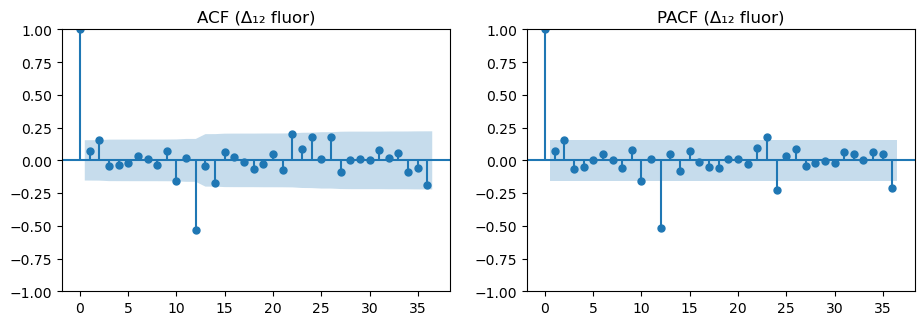

In [8]:
# Serie original de entrenamiento
y = train["fluor"]

# Serie auxiliar sin valores ausentes para los tests
y_test = y.dropna()

# Diferencia estacional de periodo 12
y_diff12 = y_test.diff(12).dropna()

print(f"Observaciones disponibles: {len(y_test)}")
print(f"ADF original          p={adfuller(y_test)[1]:.4f}")
print(f"ADF diff estacional   p={adfuller(y_diff12)[1]:.4f}")
print(f"KPSS original         p={kpss(y_test, nlags='auto')[1]:.4f}")
print(f"KPSS diff estacional  p={kpss(y_diff12, nlags='auto')[1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

plot_acf(y_diff12, lags=36, ax=axes[0])
plot_pacf(y_diff12, lags=36, ax=axes[1], method="ywm")

axes[0].set_title("ACF (Δ₁₂ fluor)")
axes[1].set_title("PACF (Δ₁₂ fluor)")

In [9]:
from itertools import product

exog_train = train["temp"].shift(1).fillna(method="bfill").values.reshape(-1, 1)

rejilla = list(product([0, 1, 2], [0, 1], [0, 1, 2], [0, 1], [0, 1], [0, 1]))
resultados = []
for p, d, q, P, D, Q in rejilla:
    try:
        m = SARIMAX(
            train["fluor"],
            exog=exog_train,
            order=(p, d, q),
            seasonal_order=(P, D, Q, 12),
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        r = m.fit(disp=False, maxiter=50)
        resultados.append({"p": p, "d": d, "q": q, "P": P, "D": D, "Q": Q, "aic": r.aic})
    except Exception:
        continue

top = pd.DataFrame(resultados).sort_values("aic").head(5)
print("Top 5 por AIC:")
print(top.to_string(index=False))

C:\Users\eva.alvarez\AppData\Local\Temp\ipykernel_33984\2793481133.py:3: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  exog_train = train["temp"].shift(1).fillna(method="bfill").values.reshape(-1, 1)
C:\Users\eva.alvarez\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\eva.alvarez\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\eva.alvarez\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\eva.alvarez\AppData\Roam

Top 5 por AIC:
 p  d  q  P  D  Q        aic
 1  0  2  0  1  1 542.573863
 0  0  2  0  1  1 542.689213
 0  0  1  0  1  1 544.102588
 2  0  2  0  1  1 544.574061
 0  0  2  1  1  1 544.689212


C:\Users\eva.alvarez\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


**Ajuste final y diagnóstico:** elegimos la mejor combinacion con AIC y diagnosticamos residuos.

Modelo elegido: SARIMAX(1, 0, 2)(0, 1, 1, 12)
AIC = 542.6   BIC = 561.5

Ljung-Box (H0: residuos = ruido blanco):
    lb_stat  lb_pvalue
12      NaN        NaN
24      NaN        NaN


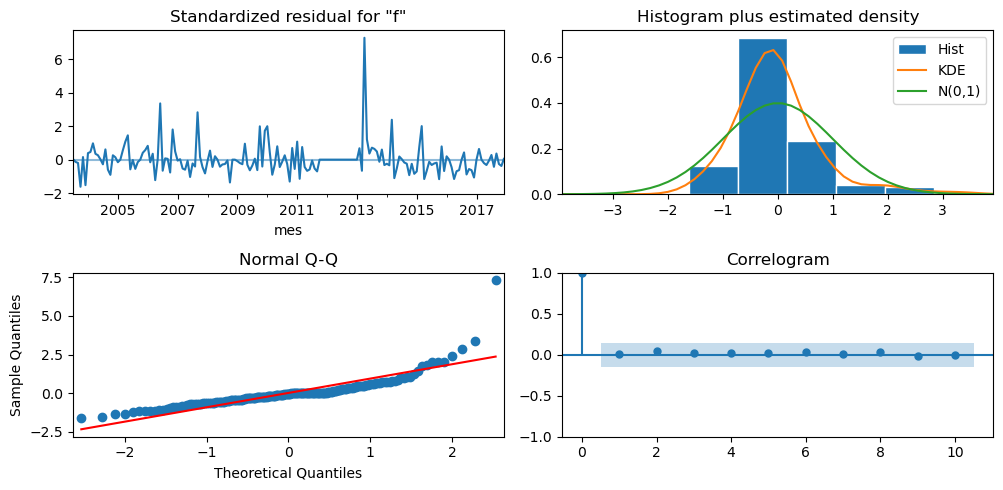

In [10]:
best = top.iloc[0]
order = (int(best["p"]), int(best["d"]), int(best["q"]))
seas = (int(best["P"]), int(best["D"]), int(best["Q"]), 12)

modelo = SARIMAX(
    train["fluor"],
    exog=exog_train,
    order=order,
    seasonal_order=seas,
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False, maxiter=200)
print(f"Modelo elegido: SARIMAX{order}{seas}")
print(f"AIC = {modelo.aic:.1f}   BIC = {modelo.bic:.1f}")

# Diagnóstico
fig = modelo.plot_diagnostics(figsize=(10, 5))
plt.tight_layout()

# Ljung-Box
lb = acorr_ljungbox(modelo.resid, lags=[12, 24], return_df=True)
print("\nLjung-Box (H0: residuos = ruido blanco):")
print(lb)

**Hacemos forecast**

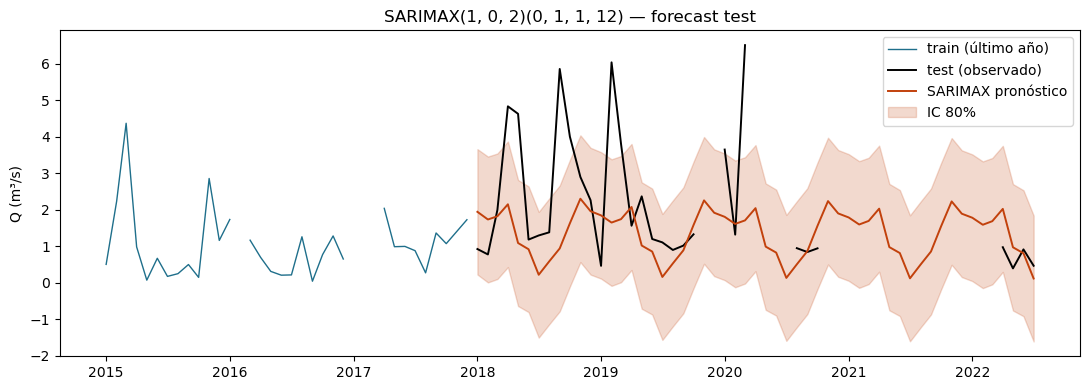

In [13]:
# Temperatura futura: media climatológica del mes
clim_temp = train["temp"].groupby(train.index.month).mean()
exog_test = test.index.month.map(clim_temp).values.reshape(-1, 1)

fc = modelo.get_forecast(steps=len(test), exog=exog_test)
media = fc.predicted_mean
ci = fc.conf_int(alpha=0.20)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    train.index[-36:], train["fluor"].iloc[-36:], color="#1f6f8b", lw=1, label="train (último año)"
)
ax.plot(test.index, test["fluor"], color="black", lw=1.4, label="test (observado)")
ax.plot(test.index, media, color="#c2410c", lw=1.4, label="SARIMAX pronóstico")
ax.fill_between(
    test.index, ci.iloc[:, 0], ci.iloc[:, 1], color="#c2410c", alpha=0.2, label="IC 80%"
)
ax.set_ylabel("Q (m³/s)")
ax.legend()
ax.set_title(f"SARIMAX{order}{seas} — forecast test")
plt.tight_layout()

1. **ETS para comparar** Nivel, tendencia y estacionalidad. Holt-Winters aditivo: sin exógenas, sólo nivel + tendencia + estacionalidad. Referencia univariante. Predice utilizando la historia de la propia clorofila.

C:\Users\eva.alvarez\AppData\Roaming\Python\Python311\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


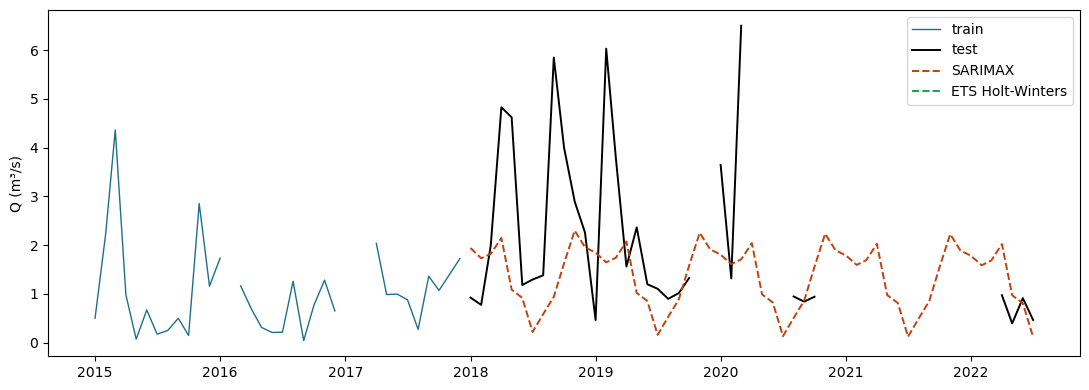

In [14]:
ets = ExponentialSmoothing(
    train["fluor"],
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated",
).fit()
pred_ets = ets.forecast(len(test))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train.index[-36:], train["fluor"].iloc[-36:], color="#1f6f8b", lw=1, label="train")
ax.plot(test.index, test["fluor"], color="black", lw=1.4, label="test")
ax.plot(test.index, media, color="#c2410c", lw=1.4, ls="--", label="SARIMAX")
ax.plot(test.index, pred_ets, color="#16a34a", lw=1.4, ls="--", label="ETS Holt-Winters")
ax.set_ylabel("Q (m³/s)")
ax.legend()
plt.tight_layout()

**Métricas RMSE / MAE**
Dependiendo del problema, puede haber métricas específicas, estas son genéricas.

In [16]:
def rmse(y, yhat):
    return float(np.sqrt(((y - yhat) ** 2).mean()))


def mae(y, yhat):
    return float((y - yhat).abs().mean())


filas = []
for nombre, pred in [("SARIMAX", media), ("ETS", pred_ets)]:
    filas.append(
        {
            "modelo": nombre,
            "RMSE (m³/s)": rmse(test["fluor"], pred),
            "MAE (m³/s)": mae(test["fluor"], pred),
        }
    )
pd.DataFrame(filas).round(3)

,modelo,RMSE (m³/s),MAE (m³/s)
0,SARIMAX,1.784,1.216
1,ETS,NaN,NaN


plot *clorofila superficie*, diferenciando periodo de entrenamiento y periodo de test.

**Comparativa de horizontes** RMSE en h=1, h=3, h=6, h=12 meses. ¿Crece el error con el horizonte?

3. Prophet
Tendencia, estacionalidad y efectos adicionales. Admite variables explicativas mediante regresores.
Sirve para comparar otra forma de representar los patrones temporales y explorar regresores adicionales.

In [22]:
import logging

logging.getLogger("cmdstanpy").setLevel(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from prophet import Prophet



In [25]:
df_prophet = pd.DataFrame({"y": df["fluor"], "temp": df["temp"]}).dropna()
df_prophet = df_prophet.reset_index().rename(columns={df_prophet.index.name or "fecha": "ds"})
df_prophet["ds"] = pd.to_datetime(df_prophet["ds"])
print(df_prophet.head())

          ds         y     temp
0 2001-04-01  0.133340  13.5672
1 2001-06-01  0.058948  16.2020
2 2001-07-01  0.033787  19.2614
3 2001-08-01  0.036313  20.8440
4 2001-09-01  0.060861  19.3269


In [ ]:
Split y ajuste

In [27]:
split = pd.Timestamp("2018-01-01")
train = df_prophet[df_prophet["ds"] < split].copy()
test = df_prophet[df_prophet["ds"] >= split].copy()

m = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    seasonality_mode="additive",
    changepoint_prior_scale=0.05,
)
m.add_regressor("temp")
m.fit(train)

17:09:02 - cmdstanpy - INFO - Chain [1] start processing
17:09:03 - cmdstanpy - INFO - Chain [1] done processing


In [28]:
# Forecast sobre las fechas de test usando la lluvia real
future = pd.concat([train[["ds", "temp"]], test[["ds", "temp"]]], ignore_index=True)
fc = m.predict(future)
fc.tail(3)[["ds", "yhat", "yhat_lower", "yhat_upper", "trend", "yearly", "temp"]]

,ds,yhat,yhat_lower,yhat_upper,trend,yearly,temp
207,2022-05-01,1.679596,0.121441,3.276789,1.702652,-0.684919,0.661863
208,2022-06-01,0.991981,-0.544611,2.574593,1.706314,0.075542,-0.789876
209,2022-07-01,1.764229,0.170278,3.279069,1.709858,0.790441,-0.736069


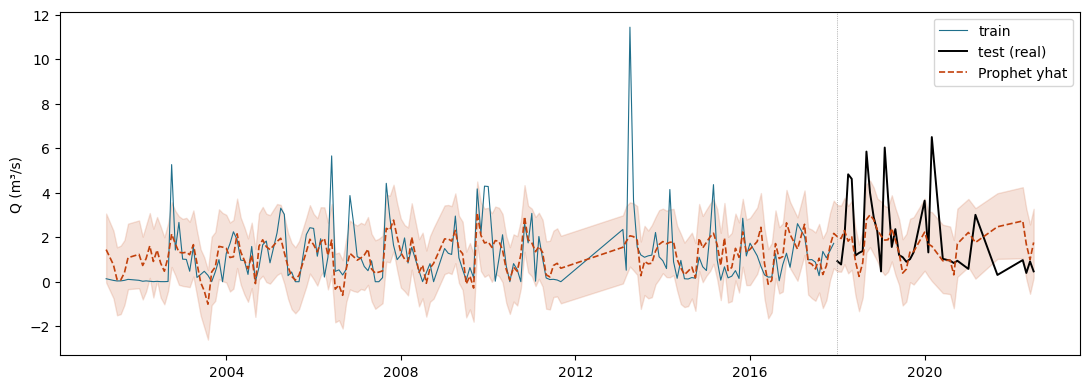

In [29]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(train["ds"], train["y"], color="#1f6f8b", lw=0.8, label="train")
ax.plot(test["ds"], test["y"], color="black", lw=1.4, label="test (real)")
ax.plot(fc["ds"], fc["yhat"], color="#c2410c", lw=1.2, ls="--", label="Prophet yhat")
ax.fill_between(fc["ds"], fc["yhat_lower"], fc["yhat_upper"], color="#c2410c", alpha=0.15)
ax.axvline(split, color="grey", lw=0.5, ls=":")
ax.set_ylabel("Q (m³/s)")
ax.legend()
plt.tight_layout()

In [ ]:
Componentes

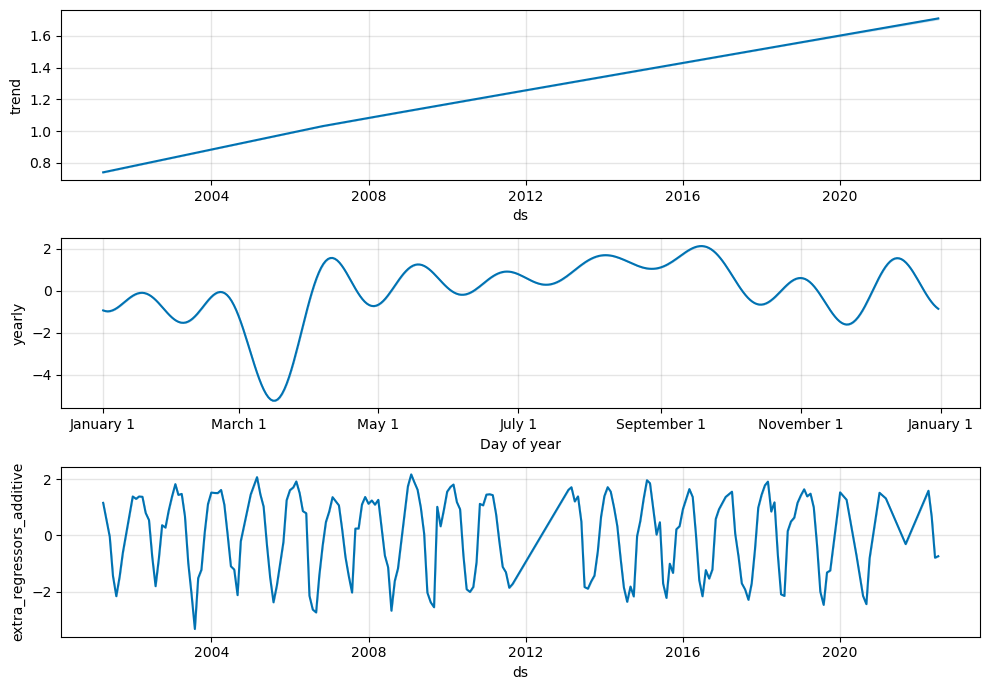

In [30]:
fig = m.plot_components(fc)
fig.set_size_inches(10, 7)
plt.tight_layout()

In [ ]:
Trend: detecta changepoints automáticamente (sequía de 2017-18 a menudo aparece como inflexión).
Yearly: ciclo anual claro con pico en marzo-abril.
Extra regressors: el coeficiente positivo de lluvia indica el aporte por unidad de mm.

5. Validación: ¿Cómo sabemos si predice razonablemente bien?

La calidad predictiva se evalúa comparando las predicciones con los valores realmente observados durante un periodo que no se haya utilizado para ajustar el modelo.
En series temporales, es importante respetar el orden cronológico. Una estrategia habitual consiste en reservar el tramo final de la serie como conjunto de prueba (test), utilizar el periodo anterior para ajustar los modelos (train) y evaluar sus predicciones sobre el periodo reservado.
La comparación debe realizarse utilizando el mismo periodo de evaluación y el mismo horizonte de predicción para todos los métodos, siempre que sea posible. También conviene compararlos con una referencia sencilla, como una predicción basada en el último valor observado o en el valor del mismo mes del año anterior, cuando esta última opción sea pertinente.

Algunas métricas habituales son:
MAE (Mean Absolute Error): error absoluto medio, expresado en las mismas unidades que la variable predicha.
RMSE (Root Mean Squared Error): raíz del error cuadrático medio, que penaliza con mayor intensidad los errores grandes.

In [31]:
pred_test = fc[fc["ds"].isin(test["ds"])].set_index("ds")["yhat"]
obs_test = test.set_index("ds")["y"]

rmse = float(np.sqrt(((obs_test - pred_test) ** 2).mean()))
mae = float((obs_test - pred_test).abs().mean())
print(f"Prophet RMSE: {rmse:.3f}   MAE: {mae:.3f}  (test 2018-2020)")

Prophet RMSE: 1.650   MAE: 1.177  (test 2018-2020)


In [ ]:
## Metricas implementacion

In [ ]:
def nse(obs, sim):
    obs, sim = np.asarray(obs), np.asarray(sim)
    return 1 - np.sum((obs - sim) ** 2) / np.sum((obs - obs.mean()) ** 2)


def kge(obs, sim):
    obs, sim = np.asarray(obs), np.asarray(sim)
    r = np.corrcoef(obs, sim)[0, 1]
    alpha = sim.std() / obs.std()
    beta = sim.mean() / obs.mean()
    return 1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)


def error_pico(obs, sim):
    return float(np.max(sim) - np.max(obs))


def rmse(obs, sim):
    return float(np.sqrt(np.mean((np.asarray(obs) - np.asarray(sim)) ** 2)))


def mae(obs, sim):
    return float(np.mean(np.abs(np.asarray(obs) - np.asarray(sim))))


# Sanity check con un caso perfecto
y = np.array([1.0, 2.0, 3.0, 4.0])
print("NSE perfecto:", nse(y, y), "  KGE perfecto:", kge(y, y))

In [ ]:
## 2 · Datos y rolling forecast (horizonte 1 mes)

Reajustamos cada modelo en cada paso y predecimos 1 mes. Mantenemos `2015-01-01` → final como periodo de evaluación.

In [ ]:
caudal_d = ud.cargar_caudal_genil(source="CEDEX")
lluvia_d = ud.cargar_lluvia_genil_diaria(fecha_inicio="1995-01-01", fecha_fin="2020-12-31")
caudal_m = caudal_d.resample("MS").mean().loc["1995":"2020"].interpolate("linear", limit=2).dropna()
lluvia_m = lluvia_d.resample("MS").sum().loc["1995":"2020"]
df = pd.DataFrame({"y": caudal_m, "lluvia": lluvia_m}).dropna()

inicio_eval = pd.Timestamp("2015-01-01")
fechas_eval = df.loc[inicio_eval:].index
print(f"Pasos de walk-forward: {len(fechas_eval)}")

In [ ]:
preds = {modelo: [] for modelo in ["SARIMAX", "ETS", "Prophet"]}
obs = []

for fecha in fechas_eval:
    historico = df.loc[:fecha].iloc[:-1]  # todo hasta el mes anterior
    objetivo = df.loc[fecha]
    obs.append(objetivo["y"])

    # --- SARIMAX(1,1,1)(1,0,1,12) con lluvia retardada ---
    exog_h = historico["lluvia"].shift(1).fillna(method="bfill").values.reshape(-1, 1)
    try:
        m_sx = SARIMAX(
            historico["y"],
            exog=exog_h,
            order=(1, 1, 1),
            seasonal_order=(1, 0, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False, maxiter=50)
        exog_fut = np.array([[historico["lluvia"].iloc[-1]]])
        preds["SARIMAX"].append(float(m_sx.forecast(steps=1, exog=exog_fut).iloc[0]))
    except Exception:
        preds["SARIMAX"].append(np.nan)

    # --- ETS Holt-Winters ---
    try:
        m_ets = ExponentialSmoothing(
            historico["y"],
            trend="add",
            seasonal="add",
            seasonal_periods=12,
            initialization_method="estimated",
        ).fit()
        preds["ETS"].append(float(m_ets.forecast(1).iloc[0]))
    except Exception:
        preds["ETS"].append(np.nan)

    # --- Prophet ---
    try:
        prh_df = historico.rename_axis("ds").reset_index()
        prh_df = prh_df.rename(columns={"y": "y"})
        m_p = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
        m_p.add_regressor("lluvia")
        m_p.fit(prh_df)
        fut = pd.DataFrame({"ds": [fecha], "lluvia": [historico["lluvia"].iloc[-1]]})
        preds["Prophet"].append(float(m_p.predict(fut)["yhat"].iloc[0]))
    except Exception:
        preds["Prophet"].append(np.nan)

obs = np.array(obs)
for k in preds:
    preds[k] = np.array(preds[k])
print("Walk-forward completado.")

In [ ]:
## Plot y metricas

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(fechas_eval, obs, color="black", lw=1.5, label="observado")
colores = {"SARIMAX": "#c2410c", "ETS": "#16a34a", "Prophet": "#7c3aed"}
for k, p in preds.items():
    ax.plot(fechas_eval, p, color=colores[k], lw=1, ls="--", label=k)
ax.set_ylabel("Q (m³/s)")
ax.legend()
ax.set_title("Walk-forward 2015-2020 — horizonte 1 mes")
plt.tight_layout()

In [ ]:
filas = []
for nombre, p in preds.items():
    mask = ~np.isnan(p)
    filas.append(
        {
            "modelo": nombre,
            "NSE": round(nse(obs[mask], p[mask]), 3),
            "KGE": round(kge(obs[mask], p[mask]), 3),
            "RMSE": round(rmse(obs[mask], p[mask]), 3),
            "MAE": round(mae(obs[mask], p[mask]), 3),
            "Error pico": round(error_pico(obs[mask], p[mask]), 3),
        }
    )
pd.DataFrame(filas).set_index("modelo")

In [ ]:
Horizonte 3. Repite el walk-forward con horizonte de 3 meses. ¿Qué modelo aguanta mejor?

6. Información adicional ¿Dónde puede profundizar quien quiera utilizarlo en investigación?

https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.ExponentialSmoothing.html

https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html

https://facebook.github.io/prophet/docs/quick_start.html   

## A mayores: Modelos estadísticos de dinámica poblacional y evaluación de stocks
Ejemplos: SAM, Stock Synthesis, SPiCT.

Representan procesos como el crecimiento, el reclutamiento, la mortalidad natural y la mortalidad por pesca. Relacionan esos procesos con observaciones disponibles —capturas, índices de abundancia, edades o tallas— y estiman variables poblacionales que no siempre se pueden observar directamente.
La diferencia fundamental es que estos modelos no se limitan a extrapolar patrones de una serie temporal. Utilizan una representación de la dinámica del stock para interpretar las observaciones y estimar cantidades de interés para la gestión, como la biomasa, la mortalidad por pesca o los puntos de referencia pesqueros.

##### **Atención** Estos métodos son fundamentales en el IEO y requerirían desarrollar una sección específica para ellos. Para profundizar en esta parte, las personas de contacto en el COG sería Marcos Llope y Paula Silvar.